# Importing Libraries and Datasets

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import pandas as pd
import seaborn as sns
import pickle
import random

import os
for dirname, _, filenames in os.walk('archive (9)'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

archive (9)\test.p
archive (9)\train.p
archive (9)\valid.p


In [2]:
with open("archive (9)/train.p", mode='rb') as training_data:
    train = pickle.load(training_data)
    
with open("archive (9)/valid.p", mode='rb') as validation_data:
    valid = pickle.load(validation_data)

with open("archive (9)/test.p", mode='rb') as testing_data:
    test = pickle.load(testing_data)

In [3]:
X_train, y_train= train['features'], train['labels']
X_validation, y_validation= valid['features'], valid['labels']
X_test, y_test= test['features'], test['labels']

# Dataset Exploration

In [4]:
X_train.shape

(34799, 32, 32, 3)

In [26]:
X_validation.shape

(4410, 32, 32, 3)

In [27]:
X_test.shape

(12630, 32, 32, 3)

In [5]:
y_train.shape

(34799,)

# Perform Data Visualization

2

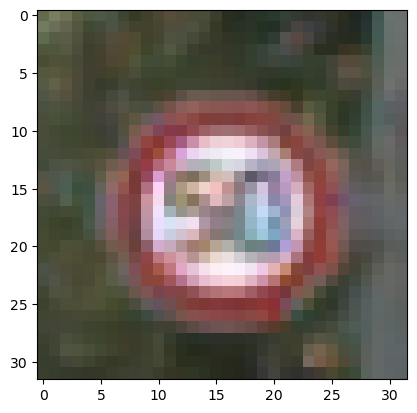

In [15]:
i = np.random.randint(1, len(X_train))
plt.imshow(X_train[i])
y_train[i]

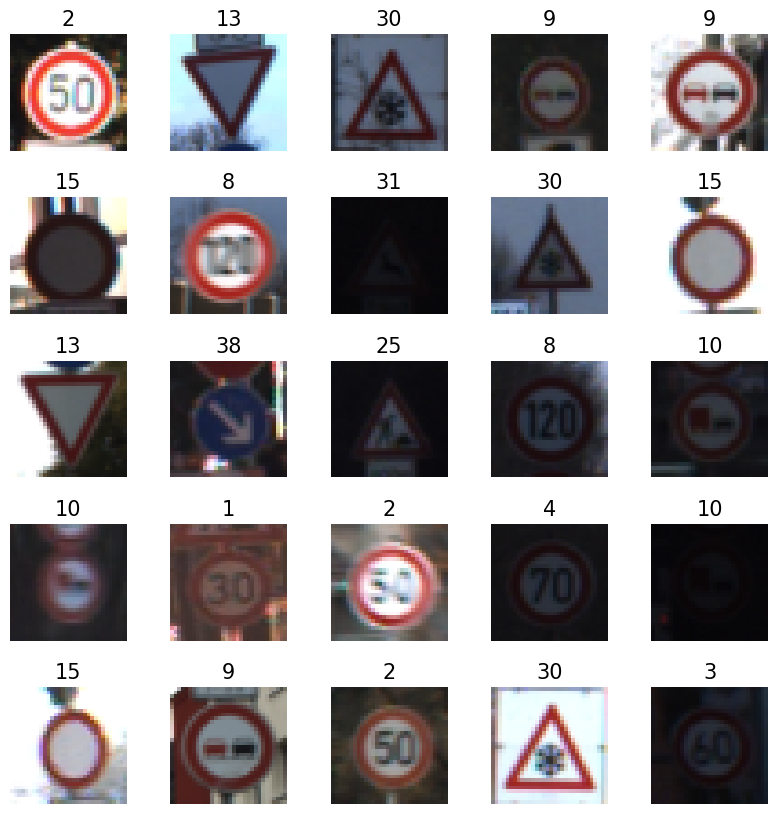

In [18]:
# Let's view more images in a grid format
# Define the dimensions of the plot grid 
W_grid = 5
L_grid = 5

# fig, axes = plt.subplots(L_grid, W_grid)
# subplot return the figure object and axes object
# we can use the axes object to plot specific figures at various locations

fig, axes = plt.subplots(L_grid, W_grid, figsize = (10,10))

axes = axes.ravel() # flaten the 5 x 5 matrix into 25 array

n_training = len(X_train) # get the length of the training dataset

# Select a random number from 0 to n_training
# create evenly spaces variables 
for i in np.arange(0, W_grid*L_grid):
    # Select a random number
    index=np.random.randint(0, n_training)
    # read and display an image with the selected index    
    axes[i].imshow(X_train[index])
    axes[i].set_title(y_train[index], fontsize=15)
    axes[i].axis("off")
    
plt.subplots_adjust(hspace=0.4)
        

# Converting RGB to GreyScale Images

In [19]:
from sklearn.utils import shuffle
X_train, y_train = shuffle(X_train, y_train)

In [20]:
X_train_gray=np.sum(X_train/3, axis=3, keepdims=True)
X_test_gray=np.sum(X_test/3, axis=3, keepdims=True)
X_validation_gray=np.sum(X_validation/3, axis=3, keepdims=True)

In [21]:
X_train_gray.shape

(34799, 32, 32, 1)

9

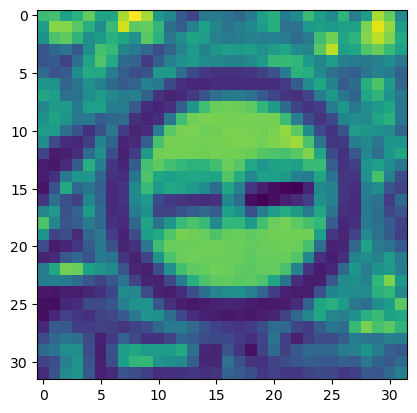

In [22]:
i = np.random.randint(1, len(X_train_gray))
plt.imshow(X_train_gray[i])
y_train[i]

In [23]:
X_train_gray_norm=(X_train_gray-128)/128
X_test_gray_norm=(X_test_gray-128)/128
X_validation_gray_norm=(X_validation_gray-128)/128

In [24]:
X_train_gray_norm

array([[[[-0.48697917],
         [-0.54166667],
         [-0.44010417],
         ...,
         [-0.53645833],
         [-0.59375   ],
         [-0.58333333]],

        [[-0.3828125 ],
         [-0.35416667],
         [-0.23697917],
         ...,
         [-0.63020833],
         [-0.60677083],
         [-0.59114583]],

        [[ 0.3046875 ],
         [ 0.08072917],
         [-0.15885417],
         ...,
         [-0.68489583],
         [-0.70572917],
         [-0.67447917]],

        ...,

        [[ 0.31770833],
         [ 0.5       ],
         [ 0.22916667],
         ...,
         [-0.44270833],
         [-0.29166667],
         [ 0.01302083]],

        [[ 0.66927083],
         [ 0.57291667],
         [ 0.44791667],
         ...,
         [-0.11197917],
         [-0.078125  ],
         [-0.18229167]],

        [[ 0.7265625 ],
         [ 0.72916667],
         [ 0.29166667],
         ...,
         [-0.0625    ],
         [-0.08333333],
         [-0.22135417]]],


       [[[-0.19270833],


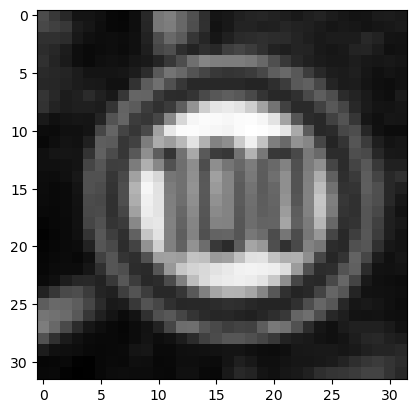

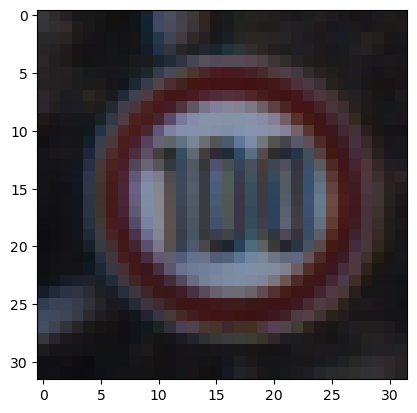

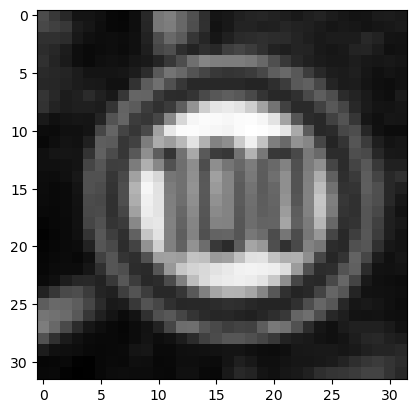

In [25]:
i = random.randint(1, len(X_train_gray))
plt.imshow(X_train_gray[i].squeeze(), cmap = 'gray')
plt.figure()
plt.imshow(X_train[i])
plt.figure()
plt.imshow(X_train_gray_norm[i].squeeze(), cmap = 'gray')

# Build the Deep Learning CNN Model

In [15]:
from tensorflow.keras import datasets, layers, models, layers
CNN=models.Sequential()

CNN.add(layers.Conv2D(6, (5,5), activation='relu', input_shape=(32,32,1)))
CNN.add(layers.AveragePooling2D())

CNN.add(layers.Dropout(0.2))

CNN.add(layers.Conv2D(16, (5,5), activation='relu'))
CNN.add(layers.AveragePooling2D())

CNN.add(layers.Flatten())

CNN.add(layers.Dense(120, activation='relu'))
CNN.add(layers.Dense(84, activation='relu'))
CNN.add(layers.Dense(43, activation='softmax'))

CNN.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 6)         156       
                                                                 
 average_pooling2d (Average  (None, 14, 14, 6)         0         
 Pooling2D)                                                      
                                                                 
 dropout (Dropout)           (None, 14, 14, 6)         0         
                                                                 
 conv2d_1 (Conv2D)           (None, 10, 10, 16)        2416      
                                                                 
 average_pooling2d_1 (Avera  (None, 5, 5, 16)          0         
 gePooling2D)                                                    
                                                                 
 flatten (Flatten)           (None, 400)               0

# Train the built CNN Model

In [27]:
CNN.compile(optimizer='Adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [17]:
history=CNN.fit(X_train_gray_norm, y_train, batch_size=500, epochs=30, verbose=1,
                validation_data=(X_validation_gray_norm, y_validation))

Epoch 1/30
70/70 [==============================] - 22s 243ms/step - loss: 3.1850 - accuracy: 0.1743 - val_loss: 2.7556 - val_accuracy: 0.3032
Epoch 2/30
70/70 [==============================] - 14s 206ms/step - loss: 1.8270 - accuracy: 0.4934 - val_loss: 1.3776 - val_accuracy: 0.5961
Epoch 3/30
70/70 [==============================] - 14s 199ms/step - loss: 1.0427 - accuracy: 0.6990 - val_loss: 1.0027 - val_accuracy: 0.7095
Epoch 4/30
70/70 [==============================] - 14s 199ms/step - loss: 0.7564 - accuracy: 0.7832 - val_loss: 0.8354 - val_accuracy: 0.7658
Epoch 5/30
70/70 [==============================] - 14s 199ms/step - loss: 0.6116 - accuracy: 0.8285 - val_loss: 0.7454 - val_accuracy: 0.7846
Epoch 6/30
70/70 [==============================] - 15s 211ms/step - loss: 0.5074 - accuracy: 0.8589 - val_loss: 0.6843 - val_accuracy: 0.8206
Epoch 7/30
70/70 [==============================] - 16s 224ms/step - loss: 0.4439 - accuracy: 0.8778 - val_loss: 0.6585 - val_accuracy: 0.8331

# Performance of the Model using Confusion Matrix

In [18]:
score = CNN.evaluate(X_test_gray_norm, y_test)
print('Test Accuracy: {}'.format(score[1]))

395/395 [==============================] - 5s 12ms/step - loss: 0.7049 - accuracy: 0.8851
Test Accuracy: 0.8851147890090942


In [19]:
history.history.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

In [20]:
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

Text(0.5, 1.0, 'Training and Validation loss')

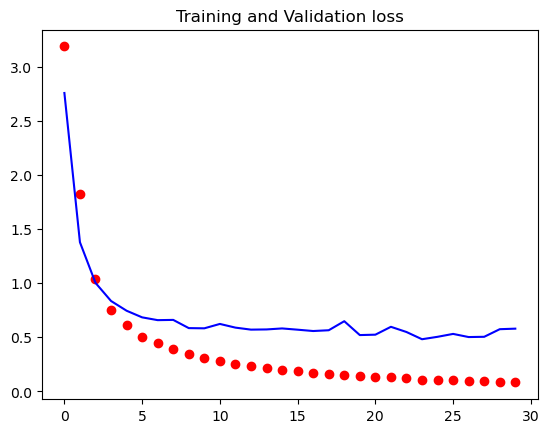

In [24]:
epochs=range(len(accuracy))
plt.plot(epochs, loss, 'ro', label='Training Loss')
plt.plot(epochs, val_loss, 'b', label='Validation Loss')
plt.title('Training and Validation loss')

Text(0.5, 1.0, 'Training and Validation Accuracy')

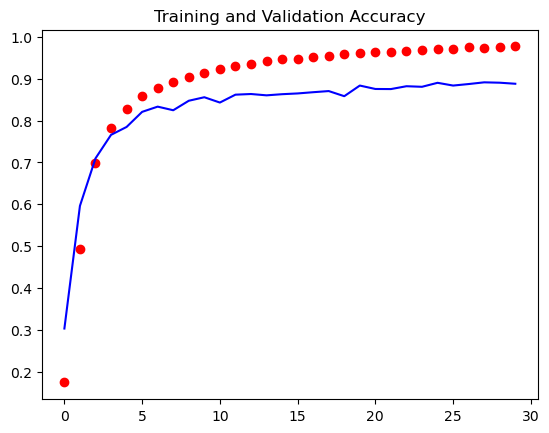

In [25]:
epochs=range(len(accuracy))
plt.plot(epochs, accuracy, 'ro', label='Training Accuracy')
plt.plot(epochs, val_accuracy, 'b', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')

395/395 [==============================] - 5s 12ms/step


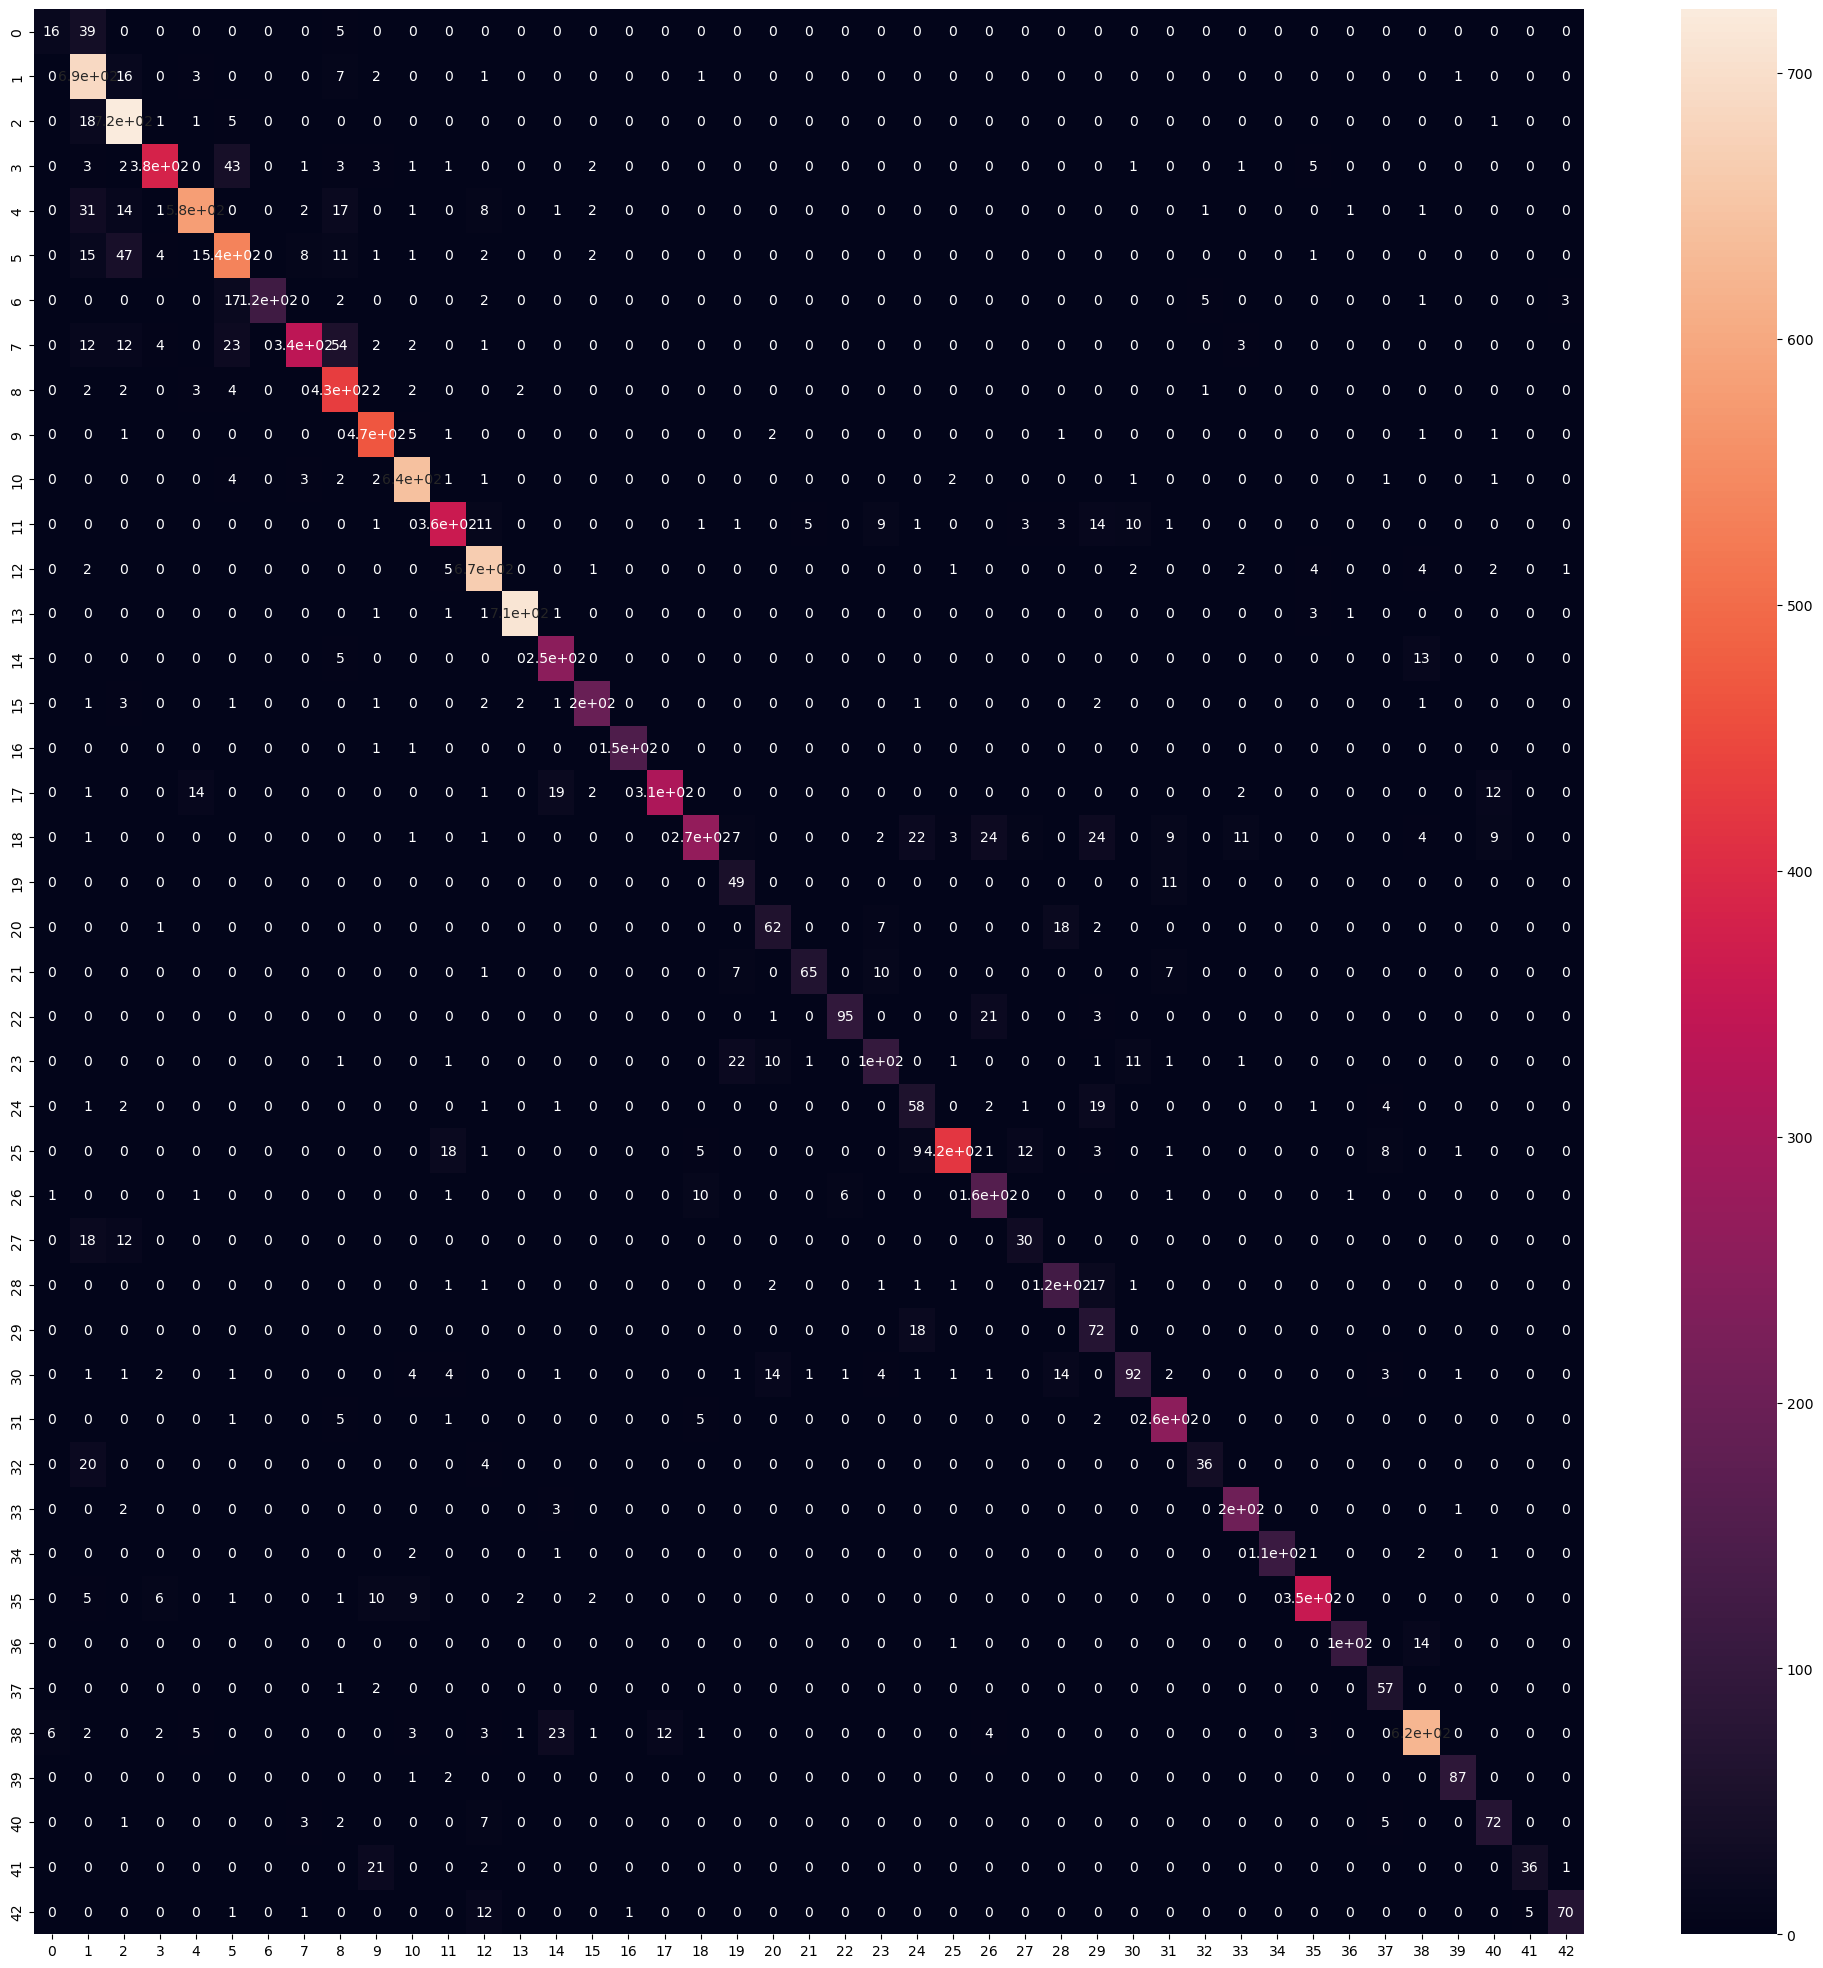

In [23]:
predicted_classes=CNN.predict(X_test_gray_norm).argmax(axis=1)
y_true = y_test

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, predicted_classes)
plt.figure(figsize = (25, 25))
sns.heatmap(cm, annot = True)
plt.show()

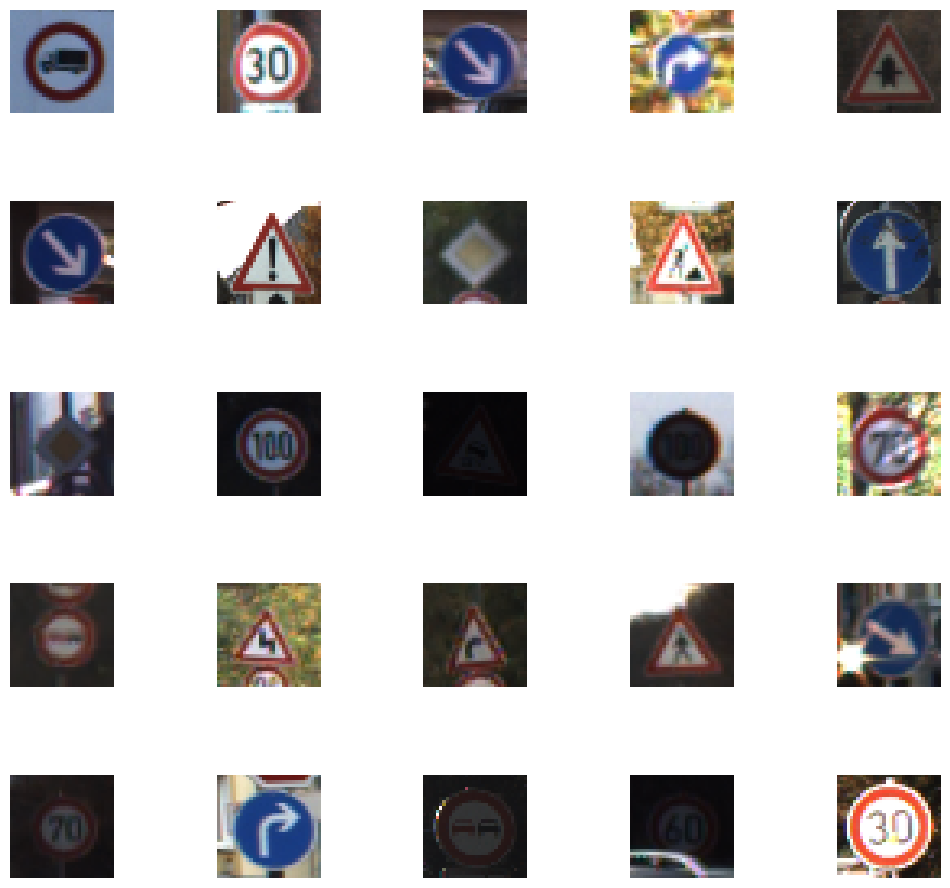

In [26]:
L = 5
W = 5

fig, axes = plt.subplots(L, W, figsize = (12, 12))
axes = axes.ravel()

for i in np.arange(0, L*W):
    axes[i].imshow(X_test[i])
    axes[i].axis('off')

plt.subplots_adjust(wspace = 1)    